# NumPy + pandas + Matplotlib for Deep Learning & Mathematical Computing

## The practical translation layer

This notebook is designed to make you fluent at turning mathematical notation and deep-learning ideas into Python code.

The target skill is not memorizing APIs. It is being able to look at something like

$$
Y = XW + b
$$

or

$$
\|x\|_2,\qquad
\frac{1}{n}\sum_i (y_i-\hat y_i)^2,\qquad
\Sigma = \frac{1}{n}X^TX
$$

and immediately know:

- what the Python objects should be,
- what their shapes should be,
- which NumPy operation implements the mathematics,
- where broadcasting is happening,
- how to reduce/sum/average along the correct axis,
- how to inspect the result,
- how to put tabular experimental data into pandas,
- and how to visualize whether your implementation is behaving correctly.

This is intentionally **code-first** and **deep-learning-oriented**.

# 0. What you should be able to do after this notebook

You should be comfortable with:

### NumPy
- arrays, dtypes, shapes, axes
- indexing and slicing
- boolean masks
- reshaping, flattening, transposing
- broadcasting
- vectorized arithmetic
- dot products and matrix multiplication
- reductions (`sum`, `mean`, `std`, `min`, `max`, ...)
- norms and distances
- `einsum`
- random number generation
- linear algebra with `np.linalg`
- solving systems without explicitly inverting matrices
- eigenvalues/eigenvectors and SVD
- batching and minibatches
- one-hot encoding
- numerical stability
- debugging shape errors

### pandas
- Series and DataFrames
- selecting rows/columns
- filtering
- missing values
- sorting
- grouping and aggregation
- merging/joining
- reshaping
- time-indexed data
- turning ML results into tables
- avoiding common alignment mistakes

### Matplotlib
- figures and axes
- line plots
- scatter plots
- histograms
- heatmaps
- images
- subplots
- labels/legends
- plotting training curves
- plotting distributions and residuals
- visualizing matrices and learned parameters

### The most important skill
You should be able to move fluently between:

**math → shapes → NumPy → pandas → visualization → sanity check**

# 1. Imports

Use NumPy for numerical arrays and linear algebra, pandas for labeled/tabular data, and Matplotlib for visualization.

For most deep-learning work, NumPy is the foundation even when the final implementation uses PyTorch/JAX/TensorFlow.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

np.set_printoptions(precision=4, suppress=True)

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)

NumPy: 2.5.3
pandas: 3.0.6


# Part I — NumPy

# 2. The central mental model: arrays + shapes

In mathematical deep learning code, the single most important question is:

> **What does each axis mean?**

For example, a supervised learning dataset might use:

$$
X \in \mathbb{R}^{N	\times D}
$$

where:
- $N$ = number of examples
- $D$ = number of features

and

$$
y \in \mathbb{R}^{N}.
$$

A neural-network hidden layer might instead use:

$$
H \in \mathbb{R}^{N	\times K}
$$

where $K$ is the number of hidden units.

In [2]:
N, D, K = 8, 5, 3

X = rng.normal(size=(N, D))
W = rng.normal(size=(D, K))
b = rng.normal(size=(K,))
y = rng.normal(size=(N,))

print("X:", X.shape)
print("W:", W.shape)
print("b:", b.shape)
print("y:", y.shape)

# Mathematical expression:
# H = XW + b
H = X @ W + b

print("H:", H.shape)

X: (8, 5)
W: (5, 3)
b: (3,)
y: (8,)
H: (8, 3)


## 3. Creating arrays

You should know these without looking them up:

- `np.array`
- `np.zeros`
- `np.ones`
- `np.full`
- `np.empty`
- `np.arange`
- `np.linspace`
- random generators
- identity matrices

In [3]:
a = np.array([1, 2, 3])
A = np.array([[1, 2], [3, 4]])

zeros = np.zeros((2, 3))
ones = np.ones((2, 3))
filled = np.full((2, 3), 7)

sequence = np.arange(0, 10, 2)
grid = np.linspace(0, 1, 6)

I = np.eye(4)

print("array:", a)
print("matrix:\n", A)
print("zeros:\n", zeros)
print("ones:\n", ones)
print("filled:\n", filled)
print("arange:", sequence)
print("linspace:", grid)
print("identity:\n", I)

array: [1 2 3]
matrix:
 [[1 2]
 [3 4]]
zeros:
 [[0. 0. 0.]
 [0. 0. 0.]]
ones:
 [[1. 1. 1.]
 [1. 1. 1.]]
filled:
 [[7 7 7]
 [7 7 7]]
arange: [0 2 4 6 8]
linspace: [0.  0.2 0.4 0.6 0.8 1. ]
identity:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


# 4. Dtypes

Mathematical values are not enough: numerical code also has a data type.

Common types:
- `float32` — common in deep learning
- `float64` — NumPy's common default for floating-point work
- `int32` / `int64`
- `bool`

You should understand that dtype affects memory, precision, and sometimes performance.

In [4]:
x64 = np.array([1., 2., 3.], dtype=np.float64)
x32 = np.array([1., 2., 3.], dtype=np.float32)
labels = np.array([0, 1, 2], dtype=np.int64)

print(x64.dtype)
print(x32.dtype)
print(labels.dtype)

print("float64 bytes:", x64.nbytes)
print("float32 bytes:", x32.nbytes)

float64
float32
int64
float64 bytes: 24
float32 bytes: 12


# 5. Shape, ndim, size, dtype

These are your first debugging tools.

In [5]:
A = rng.normal(size=(4, 3, 2))

print("shape:", A.shape)
print("ndim:", A.ndim)
print("size:", A.size)
print("dtype:", A.dtype)
print("itemsize:", A.itemsize)

shape: (4, 3, 2)
ndim: 3
size: 24
dtype: float64
itemsize: 8


# 6. Indexing and slicing

Python indexing starts at zero.

For a matrix:
- `A[i, j]` → one element
- `A[i, :]` → row
- `A[:, j]` → column
- `A[:k]` → first `k` rows
- `A[:, :k]` → first `k` columns

In [6]:
A = np.arange(1, 13).reshape(3, 4)

print(A)
print("A[1, 2] =", A[1, 2])
print("row 1 =", A[1, :])
print("column 2 =", A[:, 2])
print("first 2 rows:\n", A[:2])
print("last 2 columns:\n", A[:, -2:])

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
A[1, 2] = 7
row 1 = [5 6 7 8]
column 2 = [ 3  7 11]
first 2 rows:
 [[1 2 3 4]
 [5 6 7 8]]
last 2 columns:
 [[ 3  4]
 [ 7  8]
 [11 12]]


## 7. Views vs copies

Slicing often creates a **view**, not an independent copy.

This matters when you mutate arrays.

In [7]:
x = np.arange(5)
view = x[1:4]
view[0] = 999

print("x after modifying view:", x)

x = np.arange(5)
copy = x[1:4].copy()
copy[0] = 999

print("x after modifying copy:", x)
print("copy:", copy)

x after modifying view: [  0 999   2   3   4]
x after modifying copy: [0 1 2 3 4]
copy: [999   2   3]


# 8. Boolean masks

Boolean indexing is one of the most useful ways to translate conditions into numerical code.

For example:

$$
x_i > 0
$$

becomes `x > 0`.

In [8]:
x = np.array([-3., -1., 0., 2., 5.])

positive = x[x > 0]
nonzero = x[x != 0]
inside = x[(x >= -1) & (x <= 2)]

print("positive:", positive)
print("nonzero:", nonzero)
print("inside:", inside)

positive: [2. 5.]
nonzero: [-3. -1.  2.  5.]
inside: [-1.  0.  2.]


# 9. Vectorized arithmetic

Prefer operations on entire arrays over Python loops.

Mathematical notation such as

$$
z_i = x_i^2 + 2x_i + 1
$$

becomes one vectorized expression.

In [9]:
x = np.linspace(-3, 3, 7)

z = x**2 + 2*x + 1

print("x:", x)
print("z:", z)

x: [-3. -2. -1.  0.  1.  2.  3.]
z: [ 4.  1.  0.  1.  4.  9. 16.]


# 10. Universal functions

Know the common NumPy mathematical functions:

`np.exp`, `np.log`, `np.sqrt`, `np.abs`, `np.sin`, `np.cos`, `np.tanh`, `np.maximum`, `np.minimum`.

These are the building blocks of activation functions, likelihoods, losses, transformations, and numerical methods.

In [10]:
x = np.array([-2., -1., 0., 1., 2.])

print("exp:", np.exp(x))
print("log(exp(x)):", np.log(np.exp(x)))
print("sqrt(abs(x)):", np.sqrt(np.abs(x)))
print("tanh:", np.tanh(x))
print("ReLU:", np.maximum(x, 0))

exp: [0.1353 0.3679 1.     2.7183 7.3891]
log(exp(x)): [-2. -1.  0.  1.  2.]
sqrt(abs(x)): [1.4142 1.     0.     1.     1.4142]
tanh: [-0.964  -0.7616  0.      0.7616  0.964 ]
ReLU: [0. 0. 0. 1. 2.]


# 11. Matrix multiplication vs elementwise multiplication

This distinction causes an enormous number of beginner bugs.

- `A * B` → elementwise multiplication
- `A @ B` → matrix multiplication

In [11]:
A = np.array([[1., 2.], [3., 4.]])
B = np.array([[5., 6.], [7., 8.]])

print("A * B =\n", A * B)
print("\nA @ B =\n", A @ B)

A * B =
 [[ 5. 12.]
 [21. 32.]]

A @ B =
 [[19. 22.]
 [43. 50.]]


# 12. Dot products

For vectors,

$$
x^Ty = \sum_i x_i y_i.
$$

In NumPy:

```python
x @ y
```

or:

```python
np.dot(x, y)
```

For modern numerical code, `@` makes matrix algebra especially readable.

In [12]:
x = np.array([1., 2., 3.])
y = np.array([4., 5., 6.])

print(x @ y)
print(np.sum(x * y))
print(np.dot(x, y))

32.0
32.0
32.0


# 13. Transpose

For a matrix:

$$
A^T_{ij}=A_{ji}.
$$

Use `.T`.

Be careful: a 1-D NumPy vector has shape `(D,)`, and its transpose still has shape `(D,)`.
If you genuinely need a column matrix, use `(D, 1)`.

In [13]:
x = np.array([1., 2., 3.])

print("x shape:", x.shape)
print("x.T shape:", x.T.shape)

column = x[:, None]
row = x[None, :]

print("column:", column.shape)
print("row:", row.shape)

x shape: (3,)
x.T shape: (3,)
column: (3, 1)
row: (1, 3)


# 14. Reshape

`reshape` changes the shape without changing the element order.

This is central for:
- flattening images,
- batching,
- adding/removing singleton axes,
- preparing data for matrix multiplication.

In [14]:
x = np.arange(24)

A = x.reshape(6, 4)
B = x.reshape(2, 3, 4)

print(A.shape)
print(B.shape)
print(B)

(6, 4)
(2, 3, 4)
[[[ 0  1  2  3]
  [ 4  5  6  7]
  [ 8  9 10 11]]

 [[12 13 14 15]
  [16 17 18 19]
  [20 21 22 23]]]


## `-1` in reshape

NumPy can infer one dimension:

```python
x.reshape(batch_size, -1)
```

This is extremely common when flattening neural-network inputs.

In [15]:
images = rng.normal(size=(32, 28, 28))

flat = images.reshape(32, -1)

print("images:", images.shape)
print("flat:", flat.shape)

images: (32, 28, 28)
flat: (32, 784)


# 15. Flattening

`ravel()` and `reshape(-1)` are common ways to flatten arrays.

For machine learning, always know whether you want:
- one long vector,
- one flattened example per row,
- or a tensor preserving batch/channel/spatial dimensions.

In [16]:
image = rng.normal(size=(28, 28))

print("flatten:", image.reshape(-1).shape)
print("ravel:", image.ravel().shape)

flatten: (784,)
ravel: (784,)


# 16. Adding and removing axes

These patterns are worth memorizing:

- `x[:, None]`
- `x[None, :]`
- `np.expand_dims`
- `np.squeeze`

In [17]:
x = np.array([1., 2., 3.])

print(x.shape)
print(x[:, None].shape)
print(x[None, :].shape)
print(np.expand_dims(x, axis=1).shape)

A = np.zeros((1, 3, 1))
print("before squeeze:", A.shape)
print("after squeeze:", np.squeeze(A).shape)

(3,)
(3, 1)
(1, 3)
(3, 1)
before squeeze: (1, 3, 1)
after squeeze: (3,)


# 17. Concatenation and stacking

Useful for constructing feature matrices and batches.

- `np.concatenate` joins along an existing axis.
- `np.stack` creates a new axis.

In [18]:
a = np.array([1, 2, 3])
b = np.array([4, 5, 6])

print("concatenate:", np.concatenate([a, b]))
print("stack axis=0:\n", np.stack([a, b], axis=0))
print("stack axis=1:\n", np.stack([a, b], axis=1))

concatenate: [1 2 3 4 5 6]
stack axis=0:
 [[1 2 3]
 [4 5 6]]
stack axis=1:
 [[1 4]
 [2 5]
 [3 6]]


# 18. Broadcasting

Broadcasting is one of the most important concepts in scientific Python.

Suppose

$$
X\in R^{N	\times D},\quad b\in R^D.
$$

Then

$$
X+b
$$

adds the same bias vector to every row.

In [19]:
X = rng.normal(size=(4, 3))
b = np.array([10., 20., 30.])

Y = X + b

print("X:\n", X)
print("b:", b)
print("Y:\n", Y)

X:
 [[ 0.0359  1.7126  1.7528]
 [ 0.9046 -0.5435 -1.1925]
 [ 0.7544  1.3595 -2.0287]
 [ 1.0863 -0.2549 -1.809 ]]
b: [10. 20. 30.]
Y:
 [[10.0359 21.7126 31.7528]
 [10.9046 19.4565 28.8075]
 [10.7544 21.3595 27.9713]
 [11.0863 19.7451 28.191 ]]


## Broadcasting rule intuition

Compare dimensions from the right.

Two dimensions are compatible when:
1. they are equal, or
2. one of them is 1.

This lets you express many mathematical operations without loops.

In [20]:
X = rng.normal(size=(8, 5))
mu = X.mean(axis=0)

centered = X - mu

print("X:", X.shape)
print("mu:", mu.shape)
print("centered:", centered.shape)
print("column means after centering:", centered.mean(axis=0))

X: (8, 5)
mu: (5,)
centered: (8, 5)
column means after centering: [ 0.  0.  0. -0. -0.]


# 19. Reduction operations and `axis`

This is arguably the most important NumPy concept after shapes.

For an array $X\in R^{N	\times D}$:

- `X.mean(axis=0)` → one mean per feature
- `X.mean(axis=1)` → one mean per example
- `X.sum(axis=0)` → sum down rows
- `X.sum(axis=1)` → sum across features

Think:

> **Which axis am I eliminating?**

In [21]:
X = np.arange(12).reshape(3, 4)

print("X:\n", X)
print("sum all:", X.sum())
print("sum axis=0:", X.sum(axis=0))
print("sum axis=1:", X.sum(axis=1))
print("mean axis=0:", X.mean(axis=0))
print("mean axis=1:", X.mean(axis=1))

X:
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
sum all: 66
sum axis=0: [12 15 18 21]
sum axis=1: [ 6 22 38]
mean axis=0: [4. 5. 6. 7.]
mean axis=1: [1.5 5.5 9.5]


## Keep dimensions with `keepdims=True`

This is extremely useful for broadcasting.

If

$$
\mu = \frac{1}{N}\sum_i x_i,
$$

you may want $\mu$ to retain a singleton axis so that subtraction broadcasts exactly as intended.

In [22]:
X = rng.normal(size=(5, 3))

mu = X.mean(axis=0, keepdims=True)
centered = X - mu

print("mu shape:", mu.shape)
print("centered shape:", centered.shape)

mu shape: (1, 3)
centered shape: (5, 3)


# 20. `sum`, `mean`, `std`, `var`, `min`, `max`

Know the basic reductions and their axis behavior.

In [23]:
X = rng.normal(size=(100, 4))

stats = {
    "mean": X.mean(axis=0),
    "std": X.std(axis=0),
    "var": X.var(axis=0),
    "min": X.min(axis=0),
    "max": X.max(axis=0),
}

for name, value in stats.items():
    print(name, value)

mean [ 0.2036 -0.016   0.0121  0.1666]
std [1.0332 1.0014 1.016  0.8343]
var [1.0675 1.0027 1.0323 0.6961]
min [-2.6387 -2.9011 -3.0109 -2.0499]
max [2.6071 2.4846 3.226  2.6731]


# 21. Norms and distances

For a vector:

$$
\|x\|_2=\sqrt{\sum_i x_i^2}.
$$

Useful NumPy tools:
- `np.linalg.norm`
- `np.sqrt`
- `np.sum`
- vector subtraction

These appear everywhere in optimization and ML.

In [24]:
x = np.array([3., 4.])

l2 = np.linalg.norm(x)
l1 = np.linalg.norm(x, ord=1)
distance = np.linalg.norm(np.array([1., 2.]) - np.array([4., 6.]))

print("L2:", l2)
print("L1:", l1)
print("distance:", distance)

L2: 5.0
L1: 7.0
distance: 5.0


# 22. Einstein summation: `einsum`

You do not need to use `einsum` everywhere.

But you should be able to read it, because it provides a direct bridge between indexed mathematical notation and efficient array operations.

For example:

$$
c_i = \sum_j A_{ij}b_j
$$

can be written as:

```python
np.einsum("ij,j->i", A, b)
```

In [25]:
A = rng.normal(size=(4, 3))
b = rng.normal(size=3)

c1 = A @ b
c2 = np.einsum("ij,j->i", A, b)

print("same:", np.allclose(c1, c2))

same: True


## More `einsum` patterns worth recognizing

- `"ij,jk->ik"` → matrix multiplication
- `"i,i->"` → dot product
- `"bi,ij->bj"` → batched linear transformation
- `"bij,bjk->bik"` → batched matrix multiplication
- `"ii->"` → trace

In [26]:
A = rng.normal(size=(3, 4))
B = rng.normal(size=(4, 2))

print("matmul:",
      np.allclose(A @ B, np.einsum("ij,jk->ik", A, B)))

x = rng.normal(size=4)
print("dot:",
      np.allclose(x @ x, np.einsum("i,i->", x, x)))

M = rng.normal(size=(4, 4))
print("trace:",
      np.allclose(np.trace(M), np.einsum("ii->", M)))

matmul: True
dot: True
trace: True


# 23. Random numbers

Use a `Generator`:

```python
rng = np.random.default_rng(seed)
```

This is preferable to scattering legacy global random-state calls throughout a project.

You should know how to generate:
- uniform values
- normal values
- integers
- random choices
- permutations

In [27]:
rng = np.random.default_rng(123)

print("uniform:", rng.uniform(size=5))
print("normal:", rng.normal(size=5))
print("integers:", rng.integers(0, 10, size=5))
print("choice:", rng.choice(["A", "B", "C"], size=5))
print("permutation:", rng.permutation(10))

uniform: [0.6824 0.0538 0.2204 0.1844 0.1759]
normal: [ 0.5771 -0.6365  0.542  -0.3166 -0.3224]
integers: [0 5 2 2 2]
choice: ['C' 'C' 'A' 'B' 'C']
permutation: [2 9 0 7 4 6 8 3 5 1]


# 24. Sampling minibatches

Deep learning repeatedly takes a subset of examples:

$$
X_B = X[\mathcal B].
$$

This is simply advanced indexing.

In [28]:
N, D = 100, 6
X = rng.normal(size=(N, D))
y = rng.integers(0, 2, size=N)

batch_size = 16
indices = rng.choice(N, size=batch_size, replace=False)

X_batch = X[indices]
y_batch = y[indices]

print(X_batch.shape, y_batch.shape)

(16, 6) (16,)


# 25. One-hot encoding with NumPy

For $K$ classes, one-hot encoding turns a class index into a vector in $R^K$.

In [29]:
labels = np.array([0, 2, 1, 2])
K = 3

one_hot = np.eye(K)[labels]

print(one_hot)
print(one_hot.shape)

[[1. 0. 0.]
 [0. 0. 1.]
 [0. 1. 0.]
 [0. 0. 1.]]
(4, 3)


# 26. Softmax

A common translation:

$$
p_i = \frac{e^{z_i}}{\sum_j e^{z_j}}.
$$

The naive implementation can overflow. Stabilize it by subtracting the maximum first:

$$
\operatorname{softmax}(z)
=
\frac{e^{z-\max(z)}}{\sum_j e^{z-\max(z)}}.
$$

In [30]:
def softmax(z, axis=-1):
    z = np.asarray(z)
    shifted = z - np.max(z, axis=axis, keepdims=True)
    exp_z = np.exp(shifted)
    return exp_z / exp_z.sum(axis=axis, keepdims=True)

logits = np.array([2., 1., 0.])
p = softmax(logits)

print(p)
print("sums to:", p.sum())

[0.6652 0.2447 0.09  ]
sums to: 0.9999999999999999


# 27. Sigmoid and stable numerical thinking

$$
\sigma(x)=\frac{1}{1+e^{-x}}.
$$

For ordinary inputs the direct implementation is fine, but the broader lesson is important:

> Mathematical equivalence does not imply numerical equivalence.

Deep-learning implementations often rewrite expressions to avoid overflow, underflow, or catastrophic cancellation.

In [31]:
def sigmoid(x):
    x = np.asarray(x)
    return 1 / (1 + np.exp(-x))

x = np.linspace(-6, 6, 7)
print(sigmoid(x))

[0.0025 0.018  0.1192 0.5    0.8808 0.982  0.9975]


# 28. Log-sum-exp

The stable pattern

$$
\log\sum_i e^{x_i}
=
m+\log\sum_i e^{x_i-m},
\quad m=\max_i x_i
$$

appears constantly in probabilistic ML.

In [32]:
def logsumexp(x, axis=None, keepdims=False):
    x = np.asarray(x)
    m = np.max(x, axis=axis, keepdims=True)
    result = m + np.log(np.sum(np.exp(x - m), axis=axis, keepdims=True))
    if not keepdims:
        result = np.squeeze(result, axis=axis)
    return result

x = np.array([1000., 1001., 1002.])

print(logsumexp(x))

1002.4076059644444


# 29. Loss functions as vectorized mathematics

Mean squared error:

$$
L=\frac1N\sum_i(y_i-\hat y_i)^2.
$$

Binary cross entropy:

$$
L=-\frac1N\sum_i
[y_i\log p_i+(1-y_i)\log(1-p_i)].
$$

In [33]:
y = np.array([1., 0., 1., 1.])
p = np.array([0.9, 0.2, 0.7, 0.8])

mse = np.mean((y - p)**2)
eps = 1e-12
bce = -np.mean(y*np.log(p + eps) + (1-y)*np.log(1-p + eps))

print("MSE:", mse)
print("BCE:", bce)

MSE: 0.045
BCE: 0.22708064055498464


# 30. Covariance and matrix formulas

Suppose centered observations are rows of

$$
X_c\in R^{N	imes D}.
$$

A common covariance estimate is

$$
\Sigma=\frac{1}{N-1}X_c^TX_c.
$$

That entire formula becomes one matrix multiplication.

In [34]:
X = rng.normal(size=(200, 4))
Xc = X - X.mean(axis=0, keepdims=True)

cov_matrix = Xc.T @ Xc / (len(Xc) - 1)

print(cov_matrix)
print("symmetric:", np.allclose(cov_matrix, cov_matrix.T))

[[ 0.9466  0.0519 -0.0749 -0.0866]
 [ 0.0519  1.0427 -0.0651 -0.0759]
 [-0.0749 -0.0651  1.0386  0.0252]
 [-0.0866 -0.0759  0.0252  1.125 ]]
symmetric: True


# 31. Linear algebra with `np.linalg`

Know these functions:

- `np.linalg.norm`
- `np.linalg.solve`
- `np.linalg.inv` (understand it; don't reach for it automatically)
- `np.linalg.det`
- `np.linalg.matrix_rank`
- `np.linalg.eig`
- `np.linalg.eigh`
- `np.linalg.svd`
- `np.linalg.pinv`
- `np.linalg.lstsq`

In [35]:
A = np.array([[3., 1.],
              [1., 2.]])
b = np.array([9., 8.])

print("solve:", np.linalg.solve(A, b))
print("det:", np.linalg.det(A))
print("rank:", np.linalg.matrix_rank(A))
print("inverse:\n", np.linalg.inv(A))

solve: [2. 3.]
det: 5.000000000000001
rank: 2
inverse:
 [[ 0.4 -0.2]
 [-0.2  0.6]]


## Why `eigh` for symmetric matrices?

For real symmetric matrices, use `np.linalg.eigh`.

It exploits symmetry and returns real eigenvalues/eigenvectors in a numerically appropriate form.

In [36]:
A = np.array([[4., 1.],
              [1., 3.]])

values, vectors = np.linalg.eigh(A)

print("values:", values)
print("vectors:\n", vectors)
print("reconstruction:\n", vectors @ np.diag(values) @ vectors.T)

values: [2.382 4.618]
vectors:
 [[ 0.5257 -0.8507]
 [-0.8507 -0.5257]]
reconstruction:
 [[4. 1.]
 [1. 3.]]


# 32. SVD

For

$$
A = U\Sigma V^T
$$

use:

```python
U, s, Vt = np.linalg.svd(A, full_matrices=False)
```

NumPy returns the singular values as a vector `s`, not as a diagonal matrix.

In [37]:
A = rng.normal(size=(5, 3))

U, s, Vt = np.linalg.svd(A, full_matrices=False)

A_reconstructed = U @ np.diag(s) @ Vt

print("A:", A.shape)
print("U:", U.shape)
print("s:", s.shape)
print("Vt:", Vt.shape)
print("reconstruction error:", np.linalg.norm(A - A_reconstructed))

A: (5, 3)
U: (5, 3)
s: (3,)
Vt: (3, 3)
reconstruction error: 1.6262197585613491e-15


# 33. Pseudoinverse

The Moore–Penrose pseudoinverse is useful for least-squares and under/overdetermined systems.

NumPy:

```python
np.linalg.pinv(A)
```

You should understand the concept even when you use higher-level solvers.

In [38]:
A = rng.normal(size=(6, 3))
x_true = rng.normal(size=3)
b = A @ x_true + 0.05*rng.normal(size=6)

x_pinv = np.linalg.pinv(A) @ b
x_lstsq = np.linalg.lstsq(A, b, rcond=None)[0]

print("pseudoinverse solution:", x_pinv)
print("least-squares solution:", x_lstsq)
print("solutions close:", np.allclose(x_pinv, x_lstsq))

pseudoinverse solution: [ 0.3138  2.7371 -1.6564]
least-squares solution: [ 0.3138  2.7371 -1.6564]
solutions close: True


# 34. Batched linear algebra

Deep learning often performs the same matrix operation for many examples.

If

$$
X\in R^{B	imes D},\quad W\in R^{D	imes K},
$$

then:

$$
XW\in R^{B	imes K}.
$$

This is the fundamental pattern behind dense layers.

In [39]:
B, D, K = 32, 10, 4

X = rng.normal(size=(B, D))
W = rng.normal(size=(D, K))
b = rng.normal(size=K)

Y = X @ W + b

print(Y.shape)

(32, 4)


# 35. A mini neural-network forward pass

Now combine everything:

$$
Z=XW+b
$$

$$
H=\max(0,Z)
$$

$$
S=HW_2+b_2
$$

$$
P=\operatorname{softmax}(S).
$$

In [40]:
N, D, H, K = 64, 10, 16, 3

X = rng.normal(size=(N, D))
W1 = rng.normal(scale=0.1, size=(D, H))
b1 = np.zeros(H)
W2 = rng.normal(scale=0.1, size=(H, K))
b2 = np.zeros(K)

Z1 = X @ W1 + b1
A1 = np.maximum(Z1, 0)
logits = A1 @ W2 + b2
probs = softmax(logits, axis=1)

print("X:", X.shape)
print("Z1:", Z1.shape)
print("A1:", A1.shape)
print("logits:", logits.shape)
print("probs:", probs.shape)
print("row sums:", probs.sum(axis=1)[:5])

X: (64, 10)
Z1: (64, 16)
A1: (64, 16)
logits: (64, 3)
probs: (64, 3)
row sums: [1. 1. 1. 1. 1.]


# Part II — pandas

pandas is not a replacement for NumPy.

Use pandas when you need:
- labels,
- heterogeneous columns,
- tabular data,
- grouping,
- joining datasets,
- dates/times,
- readable experiment tables.

Then convert to NumPy when you need raw numerical linear algebra.

# 36. Series and DataFrame

A Series is essentially a labeled 1-D column.
A DataFrame is a labeled table.

In [41]:
s = pd.Series([10, 20, 30], index=["a", "b", "c"])

df = pd.DataFrame({
    "feature_1": [1.2, 2.4, 3.1],
    "feature_2": [5.0, 4.2, 6.1],
    "label": [0, 1, 1],
})

print(s)
print()
print(df)

a    10
b    20
c    30
dtype: int64

   feature_1  feature_2  label
0        1.2        5.0      0
1        2.4        4.2      1
2        3.1        6.1      1


# 37. DataFrame inspection

Know these immediately:

- `head`
- `tail`
- `shape`
- `columns`
- `dtypes`
- `describe`
- `info`
- `value_counts`

In [42]:
print(df.head())
print("\nshape:", df.shape)
print("\ncolumns:", df.columns.tolist())
print("\ndtypes:\n", df.dtypes)
print("\ndescribe:\n", df.describe())
print("\nlabels:\n", df["label"].value_counts())

   feature_1  feature_2  label
0        1.2        5.0      0
1        2.4        4.2      1
2        3.1        6.1      1

shape: (3, 3)

columns: ['feature_1', 'feature_2', 'label']

dtypes:
 feature_1    float64
feature_2    float64
label          int64
dtype: object

describe:
        feature_1  feature_2     label
count   3.000000   3.000000  3.000000
mean    2.233333   5.100000  0.666667
std     0.960902   0.953939  0.577350
min     1.200000   4.200000  0.000000
25%     1.800000   4.600000  0.500000
50%     2.400000   5.000000  1.000000
75%     2.750000   5.550000  1.000000
max     3.100000   6.100000  1.000000

labels:
 label
1    2
0    1
Name: count, dtype: int64


# 38. Selecting columns

These are the two main styles:

```python
df["feature_1"]
df[["feature_1", "feature_2"]]
```

In [43]:
print(df["feature_1"])
print()
print(df[["feature_1", "feature_2"]])

0    1.2
1    2.4
2    3.1
Name: feature_1, dtype: float64

   feature_1  feature_2
0        1.2        5.0
1        2.4        4.2
2        3.1        6.1


# 39. Selecting rows: `loc` and `iloc`

- `loc` → labels
- `iloc` → integer positions

This distinction matters once DataFrames have meaningful indexes.

In [44]:
df = pd.DataFrame(
    {"x": [10, 20, 30], "y": [1, 2, 3]},
    index=["a", "b", "c"]
)

print("loc b:")
print(df.loc["b"])

print("\niloc 1:")
print(df.iloc[1])

loc b:
x    20
y     2
Name: b, dtype: int64

iloc 1:
x    20
y     2
Name: b, dtype: int64


# 40. Filtering

Filtering is pandas' tabular analogue of NumPy boolean masks.

In [45]:
df = pd.DataFrame({
    "score": [0.2, 0.8, 0.5, 0.9],
    "class": ["A", "B", "A", "B"]
})

print(df[df["score"] > 0.7])
print()
print(df[(df["score"] > 0.4) & (df["class"] == "A")])

   score class
1    0.8     B
3    0.9     B

   score class
2    0.5     A


# 41. Creating derived columns

This is useful for feature engineering and experiment analysis.

In [46]:
df["score_squared"] = df["score"]**2
df["is_high"] = df["score"] > 0.7

print(df)

   score class  score_squared  is_high
0    0.2     A           0.04    False
1    0.8     B           0.64     True
2    0.5     A           0.25    False
3    0.9     B           0.81     True


# 42. Missing values

Know:
- `isna`
- `notna`
- `dropna`
- `fillna`

Do not blindly fill missing values. In ML, the correct treatment depends on what the missingness means.

In [47]:
df = pd.DataFrame({
    "x": [1.0, np.nan, 3.0, 4.0],
    "y": [10.0, 20.0, np.nan, 40.0]
})

print(df.isna())
print("\ncolumn missing counts:\n", df.isna().sum())

filled = df.fillna(df.mean(numeric_only=True))
print("\nfilled:\n", filled)

       x      y
0  False  False
1   True  False
2  False   True
3  False  False

column missing counts:
 x    1
y    1
dtype: int64

filled:
           x          y
0  1.000000  10.000000
1  2.666667  20.000000
2  3.000000  23.333333
3  4.000000  40.000000


# 43. Sorting

Useful for:
- ranking models,
- examining largest errors,
- inspecting feature distributions,
- sorting dates.

In [48]:
results = pd.DataFrame({
    "model": ["linear", "tree", "mlp", "svm"],
    "rmse": [0.42, 0.31, 0.28, 0.35]
})

print(results.sort_values("rmse"))

    model  rmse
2     mlp  0.28
1    tree  0.31
3     svm  0.35
0  linear  0.42


# 44. Groupby

This is one of the most useful pandas concepts for empirical ML.

For example, calculate mean performance by model:

In [49]:
results = pd.DataFrame({
    "model": ["linear", "linear", "mlp", "mlp", "tree", "tree"],
    "seed": [1, 2, 1, 2, 1, 2],
    "rmse": [0.42, 0.40, 0.28, 0.30, 0.31, 0.32]
})

summary = results.groupby("model")["rmse"].agg(["mean", "std", "min", "max"])
print(summary)

         mean       std   min   max
model                              
linear  0.410  0.014142  0.40  0.42
mlp     0.290  0.014142  0.28  0.30
tree    0.315  0.007071  0.31  0.32


# 45. Grouping multiple columns

This pattern is extremely useful for experiment logs:

```python
df.groupby(["dataset", "model"]).agg(...)
```

In [50]:
results = pd.DataFrame({
    "dataset": ["A","A","A","B","B","B"],
    "model": ["linear","mlp","tree","linear","mlp","tree"],
    "rmse": [0.5,0.3,0.35,0.7,0.45,0.5],
})

summary = results.groupby(["dataset", "model"]).agg(
    mean_rmse=("rmse", "mean"),
    best_rmse=("rmse", "min")
).reset_index()

print(summary)

  dataset   model  mean_rmse  best_rmse
0       A  linear       0.50       0.50
1       A     mlp       0.30       0.30
2       A    tree       0.35       0.35
3       B  linear       0.70       0.70
4       B     mlp       0.45       0.45
5       B    tree       0.50       0.50


# 46. Merge / join

Suppose one table contains features and another contains labels or metadata.

`merge` is the pandas equivalent of joining tables on a key.

In [51]:
features = pd.DataFrame({
    "id": [1, 2, 3],
    "x1": [0.1, 0.2, 0.3]
})

labels = pd.DataFrame({
    "id": [1, 2, 3],
    "y": [1, 0, 1]
})

merged = features.merge(labels, on="id", how="inner")
print(merged)

   id   x1  y
0   1  0.1  1
1   2  0.2  0
2   3  0.3  1


# 47. Concatenation

Use `pd.concat` when you have tables with the same schema and want to append them.

In [52]:
a = pd.DataFrame({"x": [1, 2], "y": [3, 4]})
b = pd.DataFrame({"x": [5, 6], "y": [7, 8]})

combined = pd.concat([a, b], ignore_index=True)
print(combined)

   x  y
0  1  3
1  2  4
2  5  7
3  6  8


# 48. Pivot tables

Pivoting is useful for turning experiment logs into matrices that are easy to inspect or visualize.

In [53]:
results = pd.DataFrame({
    "model": ["linear","linear","mlp","mlp"],
    "dataset": ["A","B","A","B"],
    "rmse": [0.4,0.6,0.3,0.5]
})

table = results.pivot(index="model", columns="dataset", values="rmse")
print(table)

dataset    A    B
model            
linear   0.4  0.6
mlp      0.3  0.5


# 49. Dates and time series

For quantitative finance and time-dependent ML, pandas datetime functionality is essential.

In [54]:
dates = pd.date_range("2026-01-01", periods=5, freq="D")
prices = pd.Series([100, 101, 99, 103, 104], index=dates)

print(prices)
print("\nreturns:\n", prices.pct_change())

2026-01-01    100
2026-01-02    101
2026-01-03     99
2026-01-04    103
2026-01-05    104
Freq: D, dtype: int64

returns:
 2026-01-01         NaN
2026-01-02    0.010000
2026-01-03   -0.019802
2026-01-04    0.040404
2026-01-05    0.009709
Freq: D, dtype: float64


# 50. Rolling statistics

A rolling mean is a common time-series operation:

$$
m_t=\frac{1}{k}\sum_{i=0}^{k-1}x_{t-i}.
$$

In [55]:
returns = prices.pct_change()

rolling_mean = returns.rolling(3).mean()
rolling_std = returns.rolling(3).std()

print(pd.DataFrame({
    "return": returns,
    "rolling_mean": rolling_mean,
    "rolling_std": rolling_std
}))

              return  rolling_mean  rolling_std
2026-01-01       NaN           NaN          NaN
2026-01-02  0.010000           NaN          NaN
2026-01-03 -0.019802           NaN          NaN
2026-01-04  0.040404      0.010201     0.030104
2026-01-05  0.009709      0.010104     0.030105


# 51. Converting pandas to NumPy

This is the bridge back into linear algebra.

Use:

```python
df.to_numpy()
```

or, for a single column:

```python
df["x"].to_numpy()
```

In [56]:
df = pd.DataFrame({
    "x1": [1., 2., 3.],
    "x2": [4., 5., 6.]
})

X = df.to_numpy()

print(type(X))
print(X)
print(X.shape)

<class 'numpy.ndarray'>
[[1. 4.]
 [2. 5.]
 [3. 6.]]
(3, 2)


# 52. A realistic ML preprocessing pipeline

A common workflow:

1. load table
2. select numerical features
3. convert to NumPy
4. center/scale
5. perform linear algebra
6. put results back into pandas

In [57]:
df = pd.DataFrame({
    "height": [170, 180, 175, 165, 185],
    "weight": [65, 80, 72, 58, 90],
    "target": [0.2, 0.8, 0.5, 0.1, 0.9]
})

feature_cols = ["height", "weight"]

X = df[feature_cols].to_numpy(dtype=float)
y = df["target"].to_numpy(dtype=float)

mu = X.mean(axis=0, keepdims=True)
sigma = X.std(axis=0, keepdims=True)

X_scaled = (X - mu) / sigma

print("X_scaled:\n", X_scaled)

X_scaled:
 [[-0.7071 -0.7138]
 [ 0.7071  0.6246]
 [ 0.     -0.0892]
 [-1.4142 -1.3384]
 [ 1.4142  1.5169]]


# Part III — Matplotlib

Matplotlib is your numerical debugging tool.

A plot is not decoration. In ML it can reveal:
- exploding losses,
- overfitting,
- bad normalization,
- outliers,
- broken predictions,
- class imbalance,
- strange distributions,
- unstable optimization.

# 53. The Figure / Axes mental model

The most useful pattern is:

```python
fig, ax = plt.subplots()
ax.plot(...)
```

Think of:
- `fig` = whole canvas
- `ax` = one plotting area

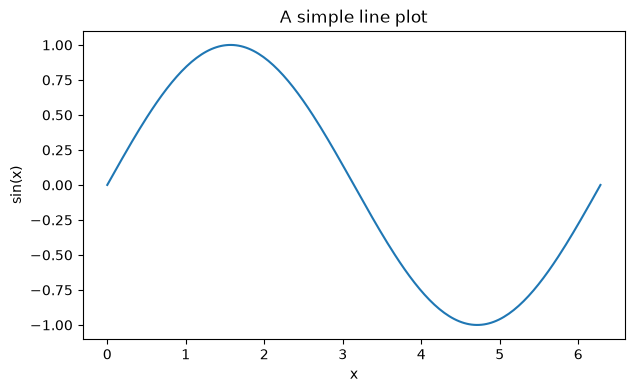

In [58]:
x = np.linspace(0, 2*np.pi, 200)
y = np.sin(x)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(x, y)
ax.set_xlabel("x")
ax.set_ylabel("sin(x)")
ax.set_title("A simple line plot")
plt.show()

# 54. Line plots

Use line plots for:
- training curves
- time series
- functions
- trajectories
- learning-rate schedules

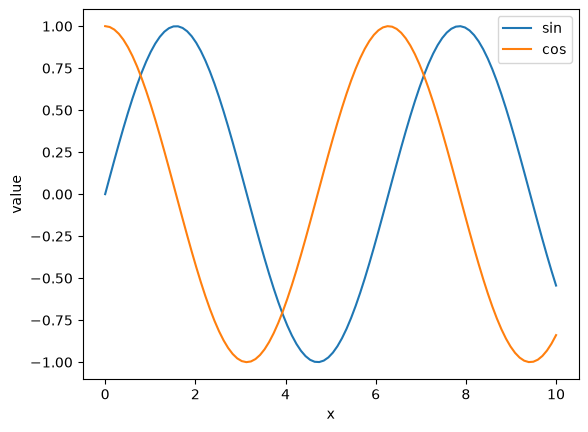

In [59]:
x = np.linspace(0, 10, 100)
y1 = np.sin(x)
y2 = np.cos(x)

fig, ax = plt.subplots()
ax.plot(x, y1, label="sin")
ax.plot(x, y2, label="cos")
ax.set_xlabel("x")
ax.set_ylabel("value")
ax.legend()
plt.show()

# 55. Scatter plots

Use scatter plots for relationships between observations.

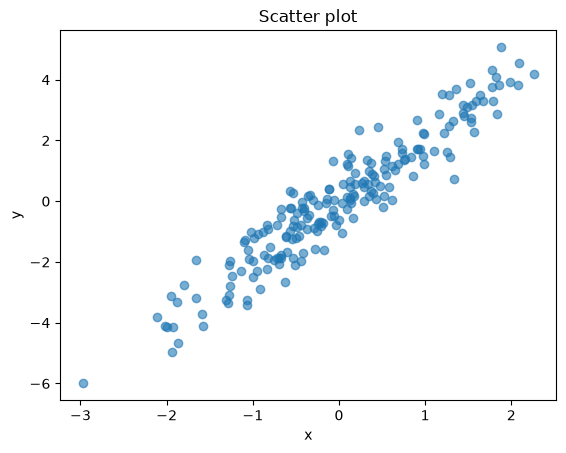

In [60]:
x = rng.normal(size=200)
y = 2*x + rng.normal(scale=0.7, size=200)

fig, ax = plt.subplots()
ax.scatter(x, y, alpha=0.6)
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title("Scatter plot")
plt.show()

# 56. Histograms

Use histograms to inspect distributions.

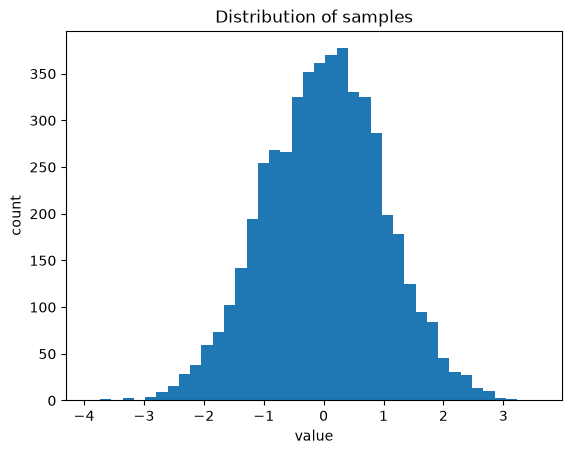

In [61]:
samples = rng.normal(size=5000)

fig, ax = plt.subplots()
ax.hist(samples, bins=40)
ax.set_xlabel("value")
ax.set_ylabel("count")
ax.set_title("Distribution of samples")
plt.show()

# 57. Heatmaps with `imshow`

Matrices are often best understood visually.

This is useful for:
- covariance matrices,
- correlation matrices,
- confusion matrices,
- attention weights,
- weight matrices,
- image tensors.

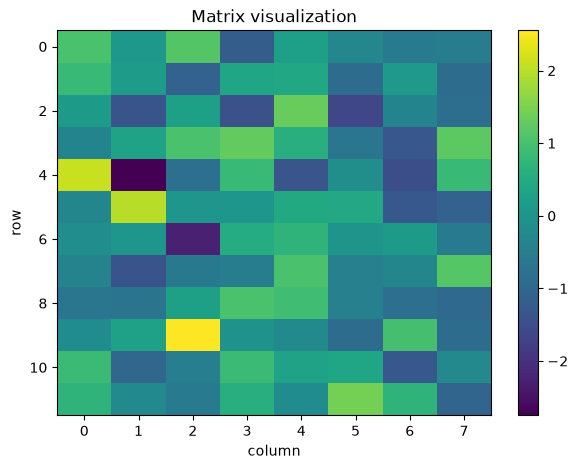

In [62]:
M = rng.normal(size=(12, 8))

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(M, aspect="auto")
fig.colorbar(im, ax=ax)
ax.set_xlabel("column")
ax.set_ylabel("row")
ax.set_title("Matrix visualization")
plt.show()

# 58. Multiple plots

Use subplots when you need to compare diagnostics.

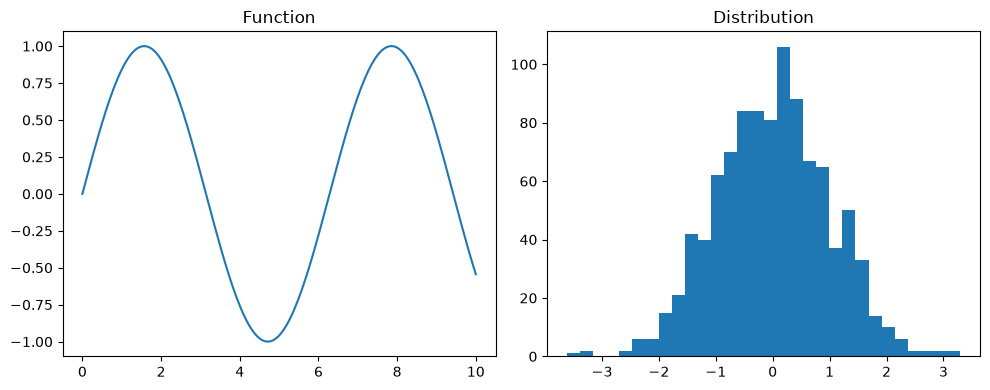

In [63]:
x = np.linspace(0, 10, 200)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].plot(x, np.sin(x))
axes[0].set_title("Function")

axes[1].hist(rng.normal(size=1000), bins=30)
axes[1].set_title("Distribution")

plt.tight_layout()
plt.show()

# 59. Training curves

This is one of the most important plots in deep learning.

Suppose we logged:

$$
L_{	ext{train}}(t),\qquad L_{	ext{val}}(t).
$$

Plot them together to diagnose optimization and overfitting.

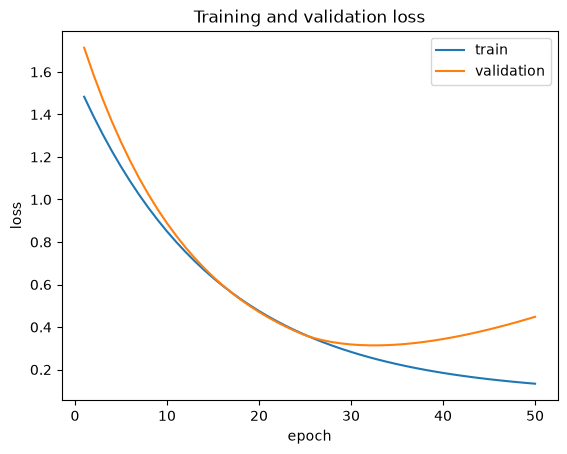

In [64]:
epochs = np.arange(1, 51)

train_loss = 1.5*np.exp(-epochs/15) + 0.08
val_loss = 1.7*np.exp(-epochs/12) + 0.15 + 0.003*np.maximum(epochs-25, 0)**1.4

fig, ax = plt.subplots()
ax.plot(epochs, train_loss, label="train")
ax.plot(epochs, val_loss, label="validation")
ax.set_xlabel("epoch")
ax.set_ylabel("loss")
ax.set_title("Training and validation loss")
ax.legend()
plt.show()

# 60. Prediction diagnostics

A useful basic diagnostic is predicted vs actual.

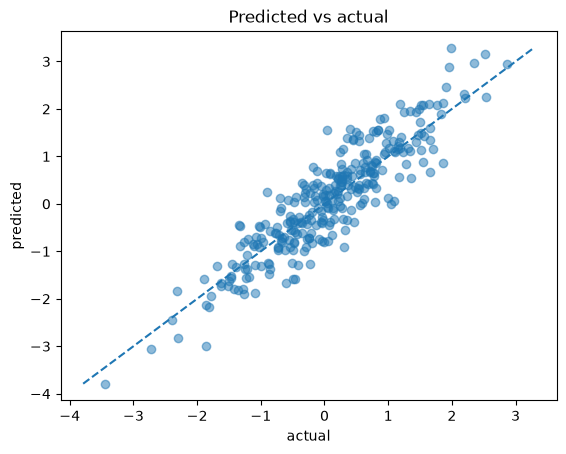

In [65]:
y_true = rng.normal(size=300)
y_pred = y_true + rng.normal(scale=0.5, size=300)

fig, ax = plt.subplots()
ax.scatter(y_true, y_pred, alpha=0.5)

lo = min(y_true.min(), y_pred.min())
hi = max(y_true.max(), y_pred.max())
ax.plot([lo, hi], [lo, hi], linestyle="--")

ax.set_xlabel("actual")
ax.set_ylabel("predicted")
ax.set_title("Predicted vs actual")
plt.show()

# 61. Residual diagnostics

Residual:

$$
r_i=y_i-\hat y_i.
$$

Plot residuals against predictions or inputs to look for systematic errors.

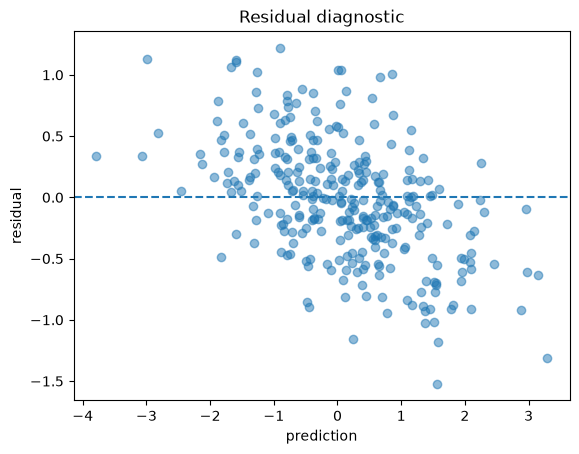

In [66]:
residuals = y_true - y_pred

fig, ax = plt.subplots()
ax.scatter(y_pred, residuals, alpha=0.5)
ax.axhline(0, linestyle="--")
ax.set_xlabel("prediction")
ax.set_ylabel("residual")
ax.set_title("Residual diagnostic")
plt.show()

# 62. Visualizing vectors

For small vectors, a bar plot is often useful.

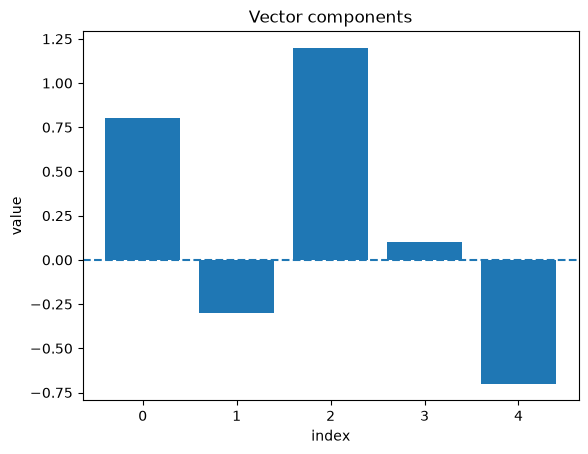

In [67]:
w = np.array([0.8, -0.3, 1.2, 0.1, -0.7])

fig, ax = plt.subplots()
ax.bar(np.arange(len(w)), w)
ax.axhline(0, linestyle="--")
ax.set_xlabel("index")
ax.set_ylabel("value")
ax.set_title("Vector components")
plt.show()

# 63. Visualizing a neural-network weight matrix

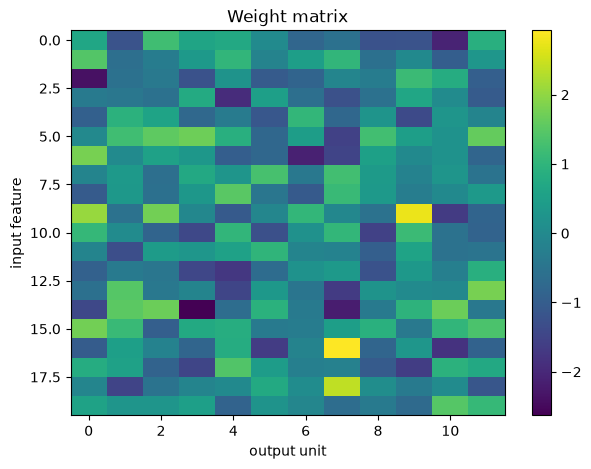

In [68]:
W = rng.normal(size=(20, 12))

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(W, aspect="auto")
fig.colorbar(im, ax=ax)
ax.set_xlabel("output unit")
ax.set_ylabel("input feature")
ax.set_title("Weight matrix")
plt.show()

# Part IV — The actual translation workflow

# 64. Math → shape → NumPy

Take:

$$
Z = XW+b
$$

Suppose:

$$
X\in R^{B	imes D},\quad
W\in R^{D	imes H},\quad
b\in R^H.
$$

Then:

$$
Z\in R^{B	imes H}.
$$

This shape reasoning should happen **before** you write the code.

In [69]:
B, D, H = 32, 10, 16

X = rng.normal(size=(B, D))
W = rng.normal(size=(D, H))
b = rng.normal(size=(H,))

Z = X @ W + b

assert X.shape == (B, D)
assert W.shape == (D, H)
assert b.shape == (H,)
assert Z.shape == (B, H)

print("Everything has the expected shape.")

Everything has the expected shape.


# 65. Example: batch mean and covariance

Math:

$$
\mu = \frac{1}{N}\sum_i x_i
$$

$$
\Sigma = \frac{1}{N-1}(X-\mu)^T(X-\mu).
$$

Code:

In [70]:
X = rng.normal(size=(500, 6))

mu = X.mean(axis=0, keepdims=True)
Xc = X - mu
Sigma = Xc.T @ Xc / (X.shape[0] - 1)

print("mu:", mu.shape)
print("Sigma:", Sigma.shape)
print("symmetric:", np.allclose(Sigma, Sigma.T))

mu: (1, 6)
Sigma: (6, 6)
symmetric: True


# 66. Example: least squares

Math:

$$
\hateta = rg\min_eta\|Xeta-y\|_2^2.
$$

In numerical code, use a least-squares solver rather than manually constructing an inverse whenever possible.

In [71]:
N, D = 100, 4

X = rng.normal(size=(N, D))
beta_true = np.array([1.5, -2., 0.5, 3.])
y = X @ beta_true + rng.normal(scale=0.5, size=N)

beta_hat = np.linalg.lstsq(X, y, rcond=None)[0]

print("true:", beta_true)
print("estimated:", beta_hat)
print("RMSE:", np.sqrt(np.mean((y - X @ beta_hat)**2)))

true: [ 1.5 -2.   0.5  3. ]
estimated: [ 1.3773 -2.0509  0.5289  3.0048]
RMSE: 0.4566675936379254


# 67. Example: PCA-style workflow

A basic PCA pipeline is a perfect exercise in translating linear algebra into code:

1. center data
2. compute covariance
3. eigendecompose covariance
4. sort eigenvalues
5. project onto leading eigenvectors
6. visualize

eigenvalues: [1.5941 0.0906]
principal component shape: (500, 1)


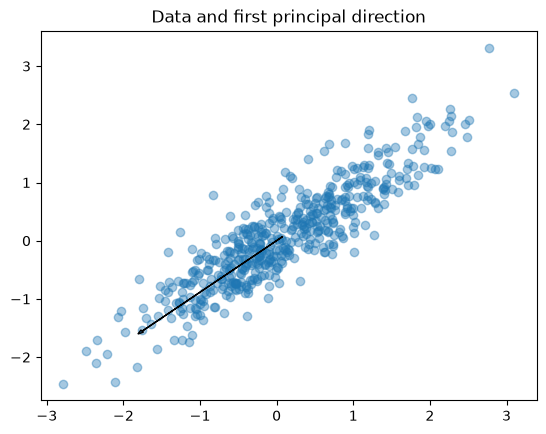

In [72]:
X = rng.normal(size=(500, 2))
X[:, 1] = 0.8*X[:, 0] + 0.4*X[:, 1]

Xc = X - X.mean(axis=0, keepdims=True)
cov = Xc.T @ Xc / (len(Xc) - 1)

eigvals, eigvecs = np.linalg.eigh(cov)
order = np.argsort(eigvals)[::-1]

eigvals = eigvals[order]
eigvecs = eigvecs[:, order]

Z = Xc @ eigvecs[:, :1]

print("eigenvalues:", eigvals)
print("principal component shape:", Z.shape)

fig, ax = plt.subplots()
ax.scatter(X[:, 0], X[:, 1], alpha=0.4)
origin = X.mean(axis=0)
direction = eigvecs[:, 0] * 2*np.sqrt(eigvals[0])
ax.arrow(origin[0], origin[1], direction[0], direction[1],
         head_width=0.05, length_includes_head=True)
ax.set_title("Data and first principal direction")
plt.show()

# 68. Example: a complete experiment table

A useful pattern for ML research is:

**NumPy computes → pandas records → Matplotlib diagnoses.**

     model  seed      rmse
0   linear     0  0.976046
1   linear     1  0.989759
2   linear     2  1.078945
3   linear     3  1.006726
4   linear     4  0.875662
5      mlp     0  0.761623
6      mlp     1  0.871420
7      mlp     2  0.675091
8      mlp     3  0.613239
9      mlp     4  0.700917
10    tree     0  0.899351
11    tree     1  0.823905
12    tree     2  0.781985
13    tree     3  0.858512
14    tree     4  0.819920

Summary:
     model  mean_rmse  std_rmse
0  linear   0.985428  0.073066
1     mlp   0.724458  0.097903
2    tree   0.836735  0.044272


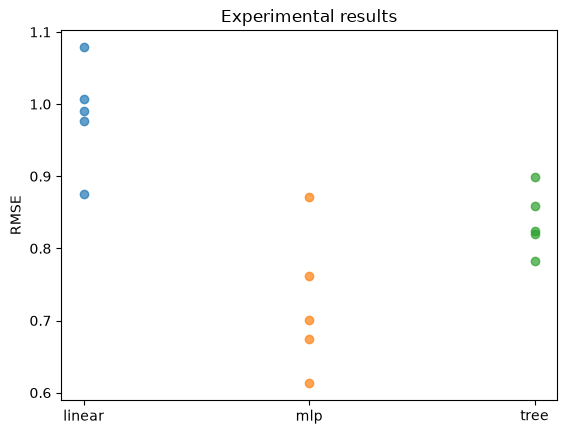

In [73]:
rows = []

for model_name, scale in [("linear", 1.0), ("mlp", 0.7), ("tree", 0.8)]:
    for seed in range(5):
        simulated_rmse = scale + 0.1*rng.normal()
        rows.append({
            "model": model_name,
            "seed": seed,
            "rmse": simulated_rmse
        })

results = pd.DataFrame(rows)

print(results)

summary = (
    results
    .groupby("model")
    .agg(mean_rmse=("rmse", "mean"),
         std_rmse=("rmse", "std"))
    .reset_index()
)

print("\nSummary:\n", summary)

fig, ax = plt.subplots()
for name, group in results.groupby("model"):
    ax.scatter([name]*len(group), group["rmse"], alpha=0.7)

ax.set_ylabel("RMSE")
ax.set_title("Experimental results")
plt.show()

# 69. Debugging shape errors systematically

When NumPy says something like:

> operands could not be broadcast together

do not randomly reshape things.

Use this checklist:

1. print every relevant `.shape`
2. write the mathematical dimensions on paper
3. identify which axis represents batch/examples/features
4. inspect whether you accidentally created `(D,)`, `(D,1)`, or `(1,D)`
5. check whether the operation is `*` or `@`
6. check the `axis=` argument
7. use `keepdims=True` when the result must broadcast back

In [74]:
# Deliberately inspect a common shape distinction.
x = rng.normal(size=5)

print("x:", x.shape)
print("x[:, None]:", x[:, None].shape)
print("x[None, :]:", x[None, :].shape)

# These are mathematically different:
print("outer product shape:", (x[:, None] @ x[None, :]).shape)

x: (5,)
x[:, None]: (5, 1)
x[None, :]: (1, 5)
outer product shape: (5, 5)


# 70. Common mistakes to eliminate

### Mistake 1
Using `*` when you mean matrix multiplication.

### Mistake 2
Forgetting that NumPy's `(D,)` is neither a row nor a column matrix.

### Mistake 3
Reducing over the wrong axis.

### Mistake 4
Using Python loops where vectorization is natural.

### Mistake 5
Using `np.linalg.inv(A) @ b` instead of `np.linalg.solve(A, b)` for a square linear system.

### Mistake 6
Ignoring numerical stability.

### Mistake 7
Converting everything to pandas even when the problem is fundamentally tensor/matrix computation.

### Mistake 8
Plotting without labels, making diagnostic plots impossible to interpret.

# 71. A compact API checklist

## NumPy — memorize these first

### Construction
`array`, `zeros`, `ones`, `full`, `arange`, `linspace`, `eye`

### Shape manipulation
`reshape`, `ravel`, `flatten`, `transpose`, `expand_dims`, `squeeze`, `concatenate`, `stack`

### Selection
indexing, slicing, boolean masks, `where`, `argmax`, `argmin`

### Arithmetic
`+`, `-`, `*`, `/`, `**`, `@`

### Reductions
`sum`, `mean`, `std`, `var`, `min`, `max`, `argmax`, `all`, `any`

### Math
`exp`, `log`, `sqrt`, `abs`, `maximum`, `minimum`, `tanh`

### Linear algebra
`norm`, `solve`, `lstsq`, `pinv`, `eig`, `eigh`, `svd`, `det`, `matrix_rank`

### Random
`default_rng`, `normal`, `uniform`, `integers`, `choice`, `permutation`

### Advanced
broadcasting, `einsum`

## pandas — memorize these first

### Inspect
`head`, `tail`, `shape`, `columns`, `dtypes`, `describe`

### Select
`[]`, `loc`, `iloc`

### Filter
boolean masks, `query`

### Transform
new columns, `assign`, `sort_values`

### Missing data
`isna`, `dropna`, `fillna`

### Combine
`merge`, `concat`

### Aggregate
`groupby`, `agg`

### Reshape
`pivot`, `pivot_table`, `melt`

### Time series
`to_datetime`, `resample`, `rolling`, `shift`, `pct_change`

### Numerical bridge
`to_numpy`

## Matplotlib — memorize these first

```python
fig, ax = plt.subplots()

ax.plot(...)
ax.scatter(...)
ax.hist(...)
ax.imshow(...)

ax.set_xlabel(...)
ax.set_ylabel(...)
ax.set_title(...)
ax.legend(...)
ax.axhline(...)
ax.axvline(...)

fig.colorbar(...)
plt.tight_layout()
plt.show()
```

The goal is not artistic mastery. The goal is to make numerical behavior visible.

# 72. Final fluency test

Without looking back, you should be able to implement each of these.

### A. Dense layer
$$
H=\operatorname{ReLU}(XW+b)
$$

### B. MSE
$$
L=\frac1N\sum_i(y_i-\hat y_i)^2
$$

### C. Standardization
$$
X'=\frac{X-\mu}{\sigma}
$$

### D. Covariance
$$
\Sigma=\frac1{N-1}X_c^TX_c
$$

### E. Least squares
$$
\hateta=rg\min_eta\|Xeta-y\|_2^2
$$

### F. Softmax
$$
p_i=\frac{e^{z_i}}{\sum_j e^{z_j}}
$$

### G. PCA
center → covariance → eigendecomposition → projection

### H. Experiment analysis
NumPy metrics → pandas summary → Matplotlib diagnostics

accuracy: 0.3828125

experiment table:
   true_class  predicted_class  confidence  correct
0           1                2    0.361334    False
1           0                2    0.378917    False
2           0                2    0.350423    False
3           2                2    0.387953     True
4           1                1    0.350026     True

summary:
             mean       std  count
correct                           
False    0.357204  0.016656    158
True     0.359829  0.016831     98


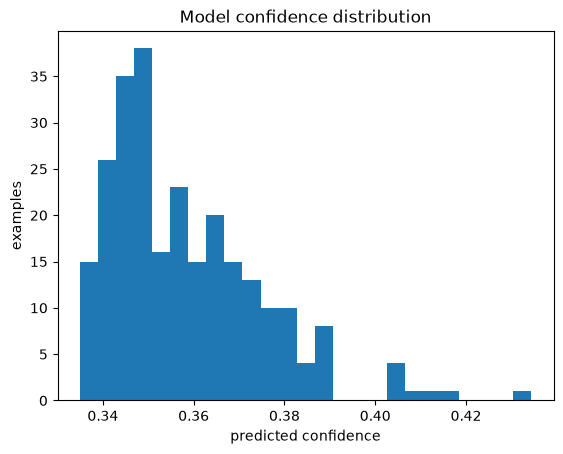

In [75]:
# Final integrated exercise / reference implementation

N, D, H, K = 256, 8, 16, 3

X = rng.normal(size=(N, D))
y = rng.integers(0, K, size=N)

W1 = rng.normal(scale=0.1, size=(D, H))
b1 = np.zeros(H)
W2 = rng.normal(scale=0.1, size=(H, K))
b2 = np.zeros(K)

# Forward pass
Z1 = X @ W1 + b1
A1 = np.maximum(Z1, 0)
logits = A1 @ W2 + b2
probs = softmax(logits, axis=1)

# Predictions and accuracy
pred = probs.argmax(axis=1)
accuracy = np.mean(pred == y)

# Record per-example results in pandas
experiment = pd.DataFrame({
    "true_class": y,
    "predicted_class": pred,
    "confidence": probs.max(axis=1),
    "correct": pred == y
})

print("accuracy:", accuracy)
print("\nexperiment table:")
print(experiment.head())

print("\nsummary:")
print(experiment.groupby("correct")["confidence"].agg(["mean", "std", "count"]))

# Visualize confidence
fig, ax = plt.subplots()
ax.hist(experiment["confidence"], bins=25)
ax.set_xlabel("predicted confidence")
ax.set_ylabel("examples")
ax.set_title("Model confidence distribution")
plt.show()

# 73. What to practice next

The point of this notebook is fluency, not completion.

A good progression is:

1. **Re-implement the exercises without looking.**
2. Take a mathematical derivation from your linear-algebra/probability notes and translate every equation into NumPy.
3. Implement a linear regression model from scratch.
4. Implement logistic regression from scratch.
5. Implement a two-layer neural network from scratch using only NumPy.
6. Use pandas to analyze its experiments.
7. Use Matplotlib to diagnose training and predictions.
8. Then move to PyTorch.

At that point, PyTorch should feel less like a mysterious framework and more like a tensor/autodiff version of operations you already understand.

## The core loop to internalize

**Read the equation → annotate dimensions → choose the array representation → implement vectorized operations → assert shapes → inspect numerical values → visualize behavior.**